In [62]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().resolve().parents[1]))

from MoE_Optimization.common.clustering_utils import get_qwen
from MoE_Optimization.common.expert_clusterer import ExpertClusterer
import os
os.getcwd()


'/glazkov-dev/MoE_Optimization/PI_EC'

In [2]:
model, tokenizer = get_qwen(cache_dir='../../.cache')

Loading weights:   0%|          | 0/387 [00:00<?, ?it/s]

In [3]:
from transformers import Qwen2MoeForCausalLM


Qwen2MoeForCausalLM

transformers.models.qwen2_moe.modeling_qwen2_moe.Qwen2MoeForCausalLM

In [4]:
model

Qwen2MoeForCausalLM(
  (model): Qwen2MoeModel(
    (embed_tokens): Embedding(151936, 2048)
    (layers): ModuleList(
      (0-23): 24 x Qwen2MoeDecoderLayer(
        (self_attn): Qwen2MoeAttention(
          (q_proj): Linear4bit(in_features=2048, out_features=2048, bias=True)
          (k_proj): Linear4bit(in_features=2048, out_features=2048, bias=True)
          (v_proj): Linear4bit(in_features=2048, out_features=2048, bias=True)
          (o_proj): Linear4bit(in_features=2048, out_features=2048, bias=False)
        )
        (mlp): Qwen2MoeSparseMoeBlock(
          (gate): Qwen2MoeTopKRouter()
          (experts): Qwen2MoeExperts(
            (act_fn): SiLUActivation()
          )
          (shared_expert): Qwen2MoeMLP(
            (gate_proj): Linear4bit(in_features=2048, out_features=5632, bias=False)
            (up_proj): Linear4bit(in_features=2048, out_features=5632, bias=False)
            (down_proj): Linear4bit(in_features=5632, out_features=2048, bias=False)
            (ac

In [5]:
from MoE_Optimization.common.clustering_utils import MMLUBatchGenerator
SELECTED_TASKS = ["anatomy",
            # "conceptual_physics",
            # "human_sexuality",
            "machine_learning",
            "management",
            # "marketing",
            # "nutrition",
             "philosophy",
            # "us_foreign_policy",
              "world_religions"]

#NOTE в оригинале было 10 тем 

# subjects = [
#            "anatomy", 
#             "conceptual_physics",
#             "human_sexuality",
#             "machine_learning", 
#             "management", 
#             "marketing", 
#             "nutrition",
#              "philosophy",
#             "us_foreign_policy",
#               "world_religions"
# ]


gen = MMLUBatchGenerator(subjects=SELECTED_TASKS, split='validation', batch_size=16, include_metadata=False)

Initialized MMLU batch generator with 5 subjects
Split: validation, Batch size: 16


В общем будет батчей и тем столько, сколько указали. На одну тему - один батч.

In [6]:
for i in iter(gen):
    
    print(i)

`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'cais/mmlu' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.



📚 Loading subject 1/5: anatomy


`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'cais/mmlu' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.


  ✓ Created batch with 14 questions
["Which of the following terms describes the body's ability to maintain its normal state?", 'Which of the following structures travel through the substance of the parotid gland?', "A medical practitioner places a stethoscope over the patient's seventh right intercostal space in the mid-axillary line. The stethoscope overlies the", 'The maxillary sinus', 'Which of the following is flexible connective tissue that is attached to bones at the joints?', 'Tonsillar tissue is commonly found', 'The best place to listen to the general heart sound with a stethoscope is the', 'Emissary veins connect the intracranial venous sinuses to', 'Smooth muscle cells contain', 'Which of the following controls body temperature, sleep, and appetite?', 'Which one of the following is brought about by activation of sympathetic nerves?', 'The trachea', 'Pharyngeal mucosa is innervated by the glossopharyngeal nerves because it develops from the', 'A patient is most likely to exp

`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'cais/mmlu' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.


  ✓ Created batch with 11 questions
['Which of the following guidelines is applicable to initialization of the weight vector in a fully connected neural network.', 'Which of the following statements about Naive Bayes is incorrect?', 'Statement 1| The L2 penalty in a ridge regression is equivalent to a Laplace prior on the weights. Statement 2| There is at least one set of 4 points in R^3 that can be shattered by the hypothesis set of all 2D planes in R^3.', 'For the one-parameter model, mean-Square error (MSE) is defined as follows: 1/(2N) \\sum (y_n − β_0)^2 . We have a half term in the front because,', "In Yann LeCun's cake, the cherry on top is", 'What is the dimensionality of the null space of the following matrix? A = [[1, 1, 1], [1, 1, 1], [1, 1, 1]]', 'The number of test examples needed to get statistically significant results should be _', 'Compared to the variance of the Maximum Likelihood Estimate (MLE), the variance of the Maximum A Posteriori (MAP) estimate is ________', 'W

`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'cais/mmlu' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.


  ✓ Created batch with 11 questions
['Simon (1960) is associated with what type of decision making model?', 'At what level of an organisation does a corporate manager operate?', 'Which one is not a recognised key skill of management?', 'Which one of the following is not a characteristic of a bureaucratic organisation?', 'To what does authority refer?', 'Power distance in national cultures is a characteristic of a model by which writer?', 'Of what is an investment decision an example?', 'How do you call a system that allows workers to work part of the week from home?', 'What are the three interpersonal roles of managers?', "According to Lewin, Lippet and White's 1939 experiment, which form of leadership produced the most work from participants?", "Which of the following motivators is the most basic need in Maslow's hierarchy?"]

📚 Loading subject 4/5: philosophy


`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'cais/mmlu' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.


  ✓ Created batch with 16 questions
['One of the aims of philosophy is to think critically about whether there are good reasons for adopting our beliefs.  Reasons are considered "good reasons" if they are consistent with everyday experience and:', 'The existence of a form of mental illness known as multiple personality disorder seems to suggest that _____.', 'Singer’s argument begins with the assumption that:', 'Interest theories of the good define goodness in terms of:', 'Brandt views his rule-utilitarianism as a:', 'Parfit claims that choosing to save the larger number in a trade-off case:', 'In Plato\'s idealism, the unchanging Ideas or "Forms" in terms of which sensible objects both exist and are known must transcend (that is, exist beyond) the changing realm of appearances; because if Forms changed, then:', 'Epictetus claims that the most important part of philosophy deals with:', 'According to Locke, the legislative power is limited by _____.', 'According to James, indeterminism 

In [7]:
from typing import *

import torch 

@torch.no_grad()
def arbitrary_input(model: torch.nn.Module, tokenizer, input: List[str]):
    inputs = tokenizer(input, return_tensors="pt",
            padding=True,  # Pad to longest in batch
            truncation=True,
            max_length=512,  # Adjust based on your needs
            add_special_tokens=True
    )
    inputs = {k: v.to(model.device) for k, v in inputs.items()}
    outputs = model(**inputs)
    return outputs

In [8]:

for batch in gen:
    inputs = tokenizer(batch, return_tensors="pt",
            padding=True,  # Pad to longest in batch
            truncation=True,
            max_length=512,  # Adjust based on your needs
            add_special_tokens=True
    )
    inputs = {k: v.to(model.device) for k, v in inputs.items()}
    print(inputs['input_ids'].shape)
    print(inputs.keys())
    print(inputs['input_ids'])
    break

`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'cais/mmlu' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.



📚 Loading subject 1/5: anatomy
  ✓ Created batch with 14 questions
torch.Size([14, 33])
dict_keys(['input_ids', 'attention_mask'])
tensor([[ 23085,    315,    279,   2701,   3793,  16555,    279,   2487,    594,
           5726,    311,  10306,   1181,   4622,   1584,     30, 151643, 151643,
         151643, 151643, 151643, 151643, 151643, 151643, 151643, 151643, 151643,
         151643, 151643, 151643, 151643, 151643, 151643],
        [ 23085,    315,    279,   2701,  14389,   5821,   1526,    279,  19699,
            315,    279,   1346,    354,    307,  66069,     30, 151643, 151643,
         151643, 151643, 151643, 151643, 151643, 151643, 151643, 151643, 151643,
         151643, 151643, 151643, 151643, 151643, 151643],
        [    32,   6457,  54372,   7482,    264,    357,    769,  62653,    916,
            279,   8720,    594,  30387,   1290,    946,  16440,    278,   3550,
            304,    279,   5099,     12,    706,  34505,   1555,     13,    576,
            357,    769

In [9]:
# model() # eats input_ids, attention, padding

In [10]:
d = {'lal': 56}
d.keys()

dict_keys(['lal'])

In [11]:
model(**inputs)

MoeCausalLMOutputWithPast(loss=None, aux_loss=None, logits=tensor([[[ 2.3086,  4.0820,  0.5015,  ..., -6.2969, -6.2969, -6.2969],
         [ 7.5898,  8.5078,  2.9355,  ...,  0.1019,  0.1019,  0.1022],
         [ 4.2539,  7.5703,  2.3789,  ..., -0.9375, -0.9370, -0.9370],
         ...,
         [ 1.2031,  5.7070,  7.0938,  ..., -7.3203, -7.3203, -7.3203],
         [ 1.4033,  6.2227,  7.5898,  ..., -7.2812, -7.2812, -7.2812],
         [ 1.1279,  5.3477,  7.1602,  ..., -7.4375, -7.4375, -7.4375]],

        [[ 2.3086,  4.0820,  0.5015,  ..., -6.2969, -6.2969, -6.2969],
         [ 7.5898,  8.5078,  2.9355,  ...,  0.1019,  0.1019,  0.1022],
         [ 4.2539,  7.5703,  2.3789,  ..., -0.9375, -0.9370, -0.9370],
         ...,
         [ 1.3584,  5.3242,  7.9219,  ..., -7.8984, -7.8984, -7.8984],
         [ 1.2285,  5.6914,  8.3984,  ..., -7.5664, -7.5664, -7.5664],
         [ 1.2949,  5.3594,  8.3594,  ..., -7.8008, -7.8008, -7.8008]],

        [[ 3.5898,  4.0078,  3.0801,  ..., -4.9336, -4.93

In [12]:
exp_clusterer = ExpertClusterer(model, [inputs]) #many batches should be, list[batch]

In [13]:
zero_layer_moe_handle = exp_clusterer.moe_handles[0]

In [14]:
activ = exp_clusterer.get_activations([zero_layer_moe_handle])

In [15]:
activ['model.layers.0.mlp.gate']

[(tensor([[0.0147, 0.0158, 0.0163,  ..., 0.0063, 0.0185, 0.0042],
          [0.0194, 0.0252, 0.0064,  ..., 0.0098, 0.0042, 0.0109],
          [0.0242, 0.0137, 0.0129,  ..., 0.0227, 0.0075, 0.0053],
          ...,
          [0.0149, 0.0320, 0.0036,  ..., 0.0159, 0.0072, 0.0002],
          [0.0133, 0.0605, 0.0041,  ..., 0.0166, 0.0043, 0.0002],
          [0.0171, 0.0256, 0.0049,  ..., 0.0329, 0.0065, 0.0003]],
         device='cuda:0'),
  tensor([[0.1042, 0.0737, 0.0665, 0.0260],
          [0.1928, 0.1127, 0.0252, 0.0245],
          [0.0947, 0.0530, 0.0268, 0.0267],
          ...,
          [0.1203, 0.0750, 0.0482, 0.0417],
          [0.1144, 0.0997, 0.0605, 0.0558],
          [0.1144, 0.0488, 0.0487, 0.0442]], device='cuda:0'),
  tensor([[33, 26,  4, 41],
          [ 4, 26,  1, 20],
          [51, 37, 13, 24],
          ...,
          [33, 35, 44, 23],
          [33, 35,  1, 44],
          [33, 23, 35, 44]], device='cuda:0'))]

In [16]:
activ['model.layers.0.mlp.gate'].__len__()

1

GATE возвращает тупл ниже
Нас интересуют logits, так как они не обрезаются до topk. Scores и indices - это по топ 4.

In [17]:
from transformers.models.qwen2_moe.modeling_qwen2_moe import Qwen2MoeSparseMoeBlock

Qwen2MoeSparseMoeBlock
activ['model.layers.0.mlp.gate'][0] #router_logits, router_scores, router_indices

(tensor([[0.0147, 0.0158, 0.0163,  ..., 0.0063, 0.0185, 0.0042],
         [0.0194, 0.0252, 0.0064,  ..., 0.0098, 0.0042, 0.0109],
         [0.0242, 0.0137, 0.0129,  ..., 0.0227, 0.0075, 0.0053],
         ...,
         [0.0149, 0.0320, 0.0036,  ..., 0.0159, 0.0072, 0.0002],
         [0.0133, 0.0605, 0.0041,  ..., 0.0166, 0.0043, 0.0002],
         [0.0171, 0.0256, 0.0049,  ..., 0.0329, 0.0065, 0.0003]],
        device='cuda:0'),
 tensor([[0.1042, 0.0737, 0.0665, 0.0260],
         [0.1928, 0.1127, 0.0252, 0.0245],
         [0.0947, 0.0530, 0.0268, 0.0267],
         ...,
         [0.1203, 0.0750, 0.0482, 0.0417],
         [0.1144, 0.0997, 0.0605, 0.0558],
         [0.1144, 0.0488, 0.0487, 0.0442]], device='cuda:0'),
 tensor([[33, 26,  4, 41],
         [ 4, 26,  1, 20],
         [51, 37, 13, 24],
         ...,
         [33, 35, 44, 23],
         [33, 35,  1, 44],
         [33, 23, 35, 44]], device='cuda:0'))

In [18]:
activ['model.layers.0.mlp.gate'][0][0]

tensor([[0.0147, 0.0158, 0.0163,  ..., 0.0063, 0.0185, 0.0042],
        [0.0194, 0.0252, 0.0064,  ..., 0.0098, 0.0042, 0.0109],
        [0.0242, 0.0137, 0.0129,  ..., 0.0227, 0.0075, 0.0053],
        ...,
        [0.0149, 0.0320, 0.0036,  ..., 0.0159, 0.0072, 0.0002],
        [0.0133, 0.0605, 0.0041,  ..., 0.0166, 0.0043, 0.0002],
        [0.0171, 0.0256, 0.0049,  ..., 0.0329, 0.0065, 0.0003]],
       device='cuda:0')

In [19]:
activ.keys()

dict_keys(['model.layers.0.mlp.gate'])

In [20]:
activ.keys()

dict_keys(['model.layers.0.mlp.gate'])

In [22]:
import torch
def count_pair_occurrences(indices):
    """
    Count occurrences of each unordered index pair across all rows.

    Args:
        indices: torch.Tensor of shape (n_samples, k), dtype=torch.long,
                 each row contains k indices (e.g., from torch.topk).

    Returns:
        unique_pairs: torch.Tensor of shape (num_unique_pairs, 2), each row is a pair (i, j) with i < j.
        counts: torch.Tensor of shape (num_unique_pairs,), counts for each pair.
    """
    n, k = indices.shape
    device = indices.device

    # All unordered column index pairs (i, j) with i < j
    col_pairs = torch.combinations(torch.arange(k, device=device), r=2)  # (m, 2)

    # Gather actual index values for these column pairs across all rows
    all_pairs = indices[:, col_pairs]  # (n, m, 2)

    # Sort each pair so that the smaller index comes first (canonical order)
    sorted_pairs, _ = torch.sort(all_pairs, dim=-1)  # (n, m, 2)

    # Flatten to a list of all pairs
    flat_pairs = sorted_pairs.view(-1, 2)  # (n*m, 2)

    # Count unique pairs
    unique_pairs, counts = torch.unique(flat_pairs, dim=0, return_counts=True)

    return unique_pairs, counts

In [23]:
import torch
from collections import Counter

def count_pair_missing(indices, co_occurrence_pairs=None, co_occurrence_counts=None):
    """
    For each unordered pair (i, j) with i < j, compute:
        - count_i_without_j : rows where i appears but j does not
        - count_j_without_i : rows where j appears but i does not

    Args:
        indices: torch.Tensor of shape (n_samples, k), dtype=torch.long
        co_occurrence_pairs: optional tensor of shape (num_pairs, 2) from previous function
        co_occurrence_counts: optional tensor of shape (num_pairs,) – if given, use them
                               to avoid recomputing co‑occurrences.

    Returns:
        result: dict or list of tuples (pair, count_i_without_j, count_j_without_i)
    """
    n, k = indices.shape
    device = indices.device

    # 1. Compute individual frequencies (how many rows contain each index)
    unique_vals, freq = torch.unique(indices, return_counts=True)
    freq_dict = {int(v): int(f) for v, f in zip(unique_vals, freq)}

    # 2. Get co‑occurrence information if not provided
    if co_occurrence_pairs is None or co_occurrence_counts is None:
        # Use the previous function (assume it's defined)
        co_occurrence_pairs, co_occurrence_counts = count_pair_occurrences(indices)

    # 3. For each pair, compute the missing counts
    result = []
    for (i, j), c in zip(co_occurrence_pairs.tolist(), co_occurrence_counts.tolist()):
        i, j = int(i), int(j)
        freq_i = freq_dict.get(i, 0)
        freq_j = freq_dict.get(j, 0)
        count_i_without_j = freq_i - c
        count_j_without_i = freq_j - c
        result.append(((i, j), count_i_without_j, count_j_without_i))

    return result


In [24]:
def coocurence_metric(gate, k=4):
    G_k = torch.topk(gate, k=k).indices
    pairs, counts = count_pair_occurrences(G_k)
    missing_stats = count_pair_missing(G_k, pairs, counts)
    
    metrics = dict(zip((tuple(p) for p in pairs.tolist()), counts))
    for pair, i_not_j, j_not_i in missing_stats:
        # metrics[pair] = metrics.get(pair, 0) ** 2 / (1 + i_not_j + j_not_i)
        metrics[pair] =( i_not_j + j_not_i) /  (metrics.get(pair, 0) + 1)
    return metrics

In [25]:
from MoE_Optimization.common.expert_logger import is_gate


def _transform_gate_activations( activations):
    '''Transform gate 3-tuples to just 1D vectors of expert's logits'''
    for layer_name in activations.keys():
        if (is_gate(layer_name)):
            activations[layer_name] = [gate[0] for gate in activations[layer_name]] #get raw logits from tuple (logits, topk scroes, topk indices)
        activations[layer_name] = torch.cat(activations[layer_name])

In [26]:
activ['model.layers.0.mlp.gate']

[(tensor([[0.0147, 0.0158, 0.0163,  ..., 0.0063, 0.0185, 0.0042],
          [0.0194, 0.0252, 0.0064,  ..., 0.0098, 0.0042, 0.0109],
          [0.0242, 0.0137, 0.0129,  ..., 0.0227, 0.0075, 0.0053],
          ...,
          [0.0149, 0.0320, 0.0036,  ..., 0.0159, 0.0072, 0.0002],
          [0.0133, 0.0605, 0.0041,  ..., 0.0166, 0.0043, 0.0002],
          [0.0171, 0.0256, 0.0049,  ..., 0.0329, 0.0065, 0.0003]],
         device='cuda:0'),
  tensor([[0.1042, 0.0737, 0.0665, 0.0260],
          [0.1928, 0.1127, 0.0252, 0.0245],
          [0.0947, 0.0530, 0.0268, 0.0267],
          ...,
          [0.1203, 0.0750, 0.0482, 0.0417],
          [0.1144, 0.0997, 0.0605, 0.0558],
          [0.1144, 0.0488, 0.0487, 0.0442]], device='cuda:0'),
  tensor([[33, 26,  4, 41],
          [ 4, 26,  1, 20],
          [51, 37, 13, 24],
          ...,
          [33, 35, 44, 23],
          [33, 35,  1, 44],
          [33, 23, 35, 44]], device='cuda:0'))]

In [27]:
_transform_gate_activations(activ)

In [28]:
# torch.cat(activ['model.layers.0.mlp.gate'])

In [29]:
activ['model.layers.0.mlp.gate'].shape

torch.Size([462, 60])

In [30]:
cooc = coocurence_metric(activ['model.layers.0.mlp.gate'], k=4)

In [31]:
cooc

{(0, 2): tensor(13., device='cuda:0'),
 (0, 3): tensor(6.6667, device='cuda:0'),
 (0, 12): tensor(17., device='cuda:0'),
 (0, 13): tensor(44., device='cuda:0'),
 (0, 14): tensor(10., device='cuda:0'),
 (0, 19): tensor(14., device='cuda:0'),
 (0, 22): tensor(12.5000, device='cuda:0'),
 (0, 23): tensor(33.2500, device='cuda:0'),
 (0, 24): tensor(9.6000, device='cuda:0'),
 (0, 29): tensor(14., device='cuda:0'),
 (0, 33): tensor(39.5714, device='cuda:0'),
 (0, 35): tensor(41., device='cuda:0'),
 (0, 39): tensor(27., device='cuda:0'),
 (0, 41): tensor(17.5000, device='cuda:0'),
 (0, 48): tensor(6.5556, device='cuda:0'),
 (0, 49): tensor(14.5000, device='cuda:0'),
 (0, 52): tensor(11.5000, device='cuda:0'),
 (0, 53): tensor(3.8000, device='cuda:0'),
 (0, 54): tensor(14., device='cuda:0'),
 (0, 57): tensor(18.3333, device='cuda:0'),
 (0, 58): tensor(17.5000, device='cuda:0'),
 (1, 2): tensor(24.5000, device='cuda:0'),
 (1, 3): tensor(15., device='cuda:0'),
 (1, 4): tensor(6.6667, device='cuda

In [32]:
def build_heatmap_matrix(pair_dict, num_experts, device='cpu'):
    """
    Convert a dictionary of (i, j) -> value into a symmetric 2D matrix.

    Args:
        pair_dict: dict with keys as tuples (i, j) and values as torch.Tensor scalars
        num_experts: total number of experts (indices from 0 to num_experts-1)
        device: torch device for the output tensor

    Returns:
        matrix: torch.Tensor of shape (num_experts, num_experts)
    """
    matrix = torch.zeros((num_experts, num_experts), device=device)
    for (i, j), val in pair_dict.items():
        # Ensure val is a scalar tensor (detach, move to correct device)
        v = val.to(device).detach()
        matrix[i, j] = v
        matrix[j, i] = v   # symmetric for heatmap
    return matrix

In [33]:
build_heatmap_matrix(cooc, 60)

tensor([[ 0.0000,  0.0000, 13.0000,  ..., 18.3333, 17.5000,  0.0000],
        [ 0.0000,  0.0000, 24.5000,  ...,  0.0000,  0.0000,  0.0000],
        [13.0000, 24.5000,  0.0000,  ..., 16.0000,  0.0000, 14.0000],
        ...,
        [18.3333,  0.0000, 16.0000,  ...,  0.0000, 14.5000,  0.0000],
        [17.5000,  0.0000,  0.0000,  ..., 14.5000,  0.0000,  0.0000],
        [ 0.0000,  0.0000, 14.0000,  ...,  0.0000,  0.0000,  0.0000]])

The end of converting activations to matrix!

In [34]:
def get_raw_cooc_counts(gate, k=4) -> dict:
    """Возвращает словарь с сырыми частотами совместной встречаемости пар."""
    G_k = torch.topk(gate, k=k).indices
    pairs, counts = count_pair_occurrences(G_k)
    return dict(zip((tuple(p) for p in pairs.tolist()), counts.tolist()))

In [40]:
d = get_raw_cooc_counts(activ['model.layers.0.mlp.gate'])
d

{(0, 2): 2,
 (0, 3): 2,
 (0, 12): 1,
 (0, 13): 1,
 (0, 14): 1,
 (0, 19): 1,
 (0, 22): 1,
 (0, 23): 3,
 (0, 24): 4,
 (0, 29): 1,
 (0, 33): 6,
 (0, 35): 3,
 (0, 39): 1,
 (0, 41): 1,
 (0, 48): 8,
 (0, 49): 1,
 (0, 52): 3,
 (0, 53): 4,
 (0, 54): 1,
 (0, 57): 2,
 (0, 58): 1,
 (1, 2): 1,
 (1, 3): 1,
 (1, 4): 5,
 (1, 5): 1,
 (1, 7): 1,
 (1, 10): 3,
 (1, 13): 1,
 (1, 14): 1,
 (1, 15): 6,
 (1, 16): 3,
 (1, 20): 4,
 (1, 23): 1,
 (1, 26): 4,
 (1, 32): 1,
 (1, 33): 6,
 (1, 34): 1,
 (1, 35): 5,
 (1, 36): 6,
 (1, 37): 1,
 (1, 39): 4,
 (1, 40): 1,
 (1, 44): 5,
 (1, 46): 2,
 (1, 47): 2,
 (1, 48): 1,
 (1, 54): 3,
 (1, 55): 1,
 (1, 56): 1,
 (2, 5): 2,
 (2, 14): 1,
 (2, 15): 1,
 (2, 16): 1,
 (2, 17): 2,
 (2, 19): 9,
 (2, 21): 1,
 (2, 23): 5,
 (2, 25): 5,
 (2, 26): 2,
 (2, 29): 3,
 (2, 30): 1,
 (2, 31): 1,
 (2, 32): 3,
 (2, 36): 8,
 (2, 37): 3,
 (2, 38): 1,
 (2, 39): 4,
 (2, 40): 1,
 (2, 41): 3,
 (2, 43): 7,
 (2, 44): 2,
 (2, 48): 2,
 (2, 49): 1,
 (2, 53): 1,
 (2, 54): 2,
 (2, 55): 1,
 (2, 56): 1,
 (2, 57

In [36]:
import numpy as np
# pairwise isolation - метрика для пар экспертов
def PI_score(expert1: int, expert2: int, cooc: dict, k: int=4) -> float:
    """
    Вычисляет PI-метрику между двумя экспертами.
    PI = количество их встреч парой / сумма встреч каждого из них с другими экспертами
    """
    
    pair_key = tuple(sorted((expert1, expert2)))
    cooc_count = cooc.get(pair_key, 0)
    
    # Считаем общее количество встреч для каждого эксперта
    total_expert1 = sum(count for (e1, e2), count in cooc.items() if e1 == expert1 or e2 == expert1)
    total_expert2 = sum(count for (e1, e2), count in cooc.items() if e1 == expert2 or e2 == expert2)
    
    pi_value = cooc_count / (total_expert1 + total_expert2 - 2 * cooc_count + 1) 
    return pi_value

# exclusivity 
def EC_score(expert1: int, expert2: int, cooc: dict, k: int=4) -> float:
    """
    Вычисляет EC-метрику для одного эксперта.
    EC = сумма встреч каждого эксперта с другими экспертами / количество их встреч парой
    """

    pair_key = tuple(sorted((expert1, expert2)))
    cooc_count = cooc.get(pair_key, 0)
    
    # Считаем общее количество встреч для каждого эксперта
    total_expert1 = sum(count for (e1, e2), count in cooc.items() if e1 == expert1 or e2 == expert1)
    total_expert2 = sum(count for (e1, e2), count in cooc.items() if e1 == expert2 or e2 == expert2)
    
    ec_value = (total_expert1 + total_expert2 - 2 * cooc_count) / (cooc_count + 1)  
    return ec_value

def compute_EC_matrix(num_experts: int, gate: torch.Tensor, k: int=4) -> np.ndarray:
    ec_matrix = torch.zeros((num_experts, num_experts))
    raw_cooc = get_raw_cooc_counts(gate, k)   
    for i in range(num_experts):
        for j in range(i + 1, num_experts):
            ec_value = EC_score(i, j, raw_cooc, k)
            ec_matrix[i, j] = ec_value
            ec_matrix[j, i] = ec_value  
    return ec_matrix

def compute_PI_matrix(num_experts: int, gate: torch.Tensor, k: int=4) -> np.ndarray:
    pi_matrix = torch.zeros((num_experts, num_experts))
    raw_cooc = get_raw_cooc_counts(gate, k)
    for i in range(num_experts):
        for j in range(i + 1, num_experts):
            pi_value = PI_score(i, j, raw_cooc, k)
            pi_matrix[i, j] = pi_value
            pi_matrix[j, i] = pi_value  
    return pi_matrix

In [ ]:
Qwen2MoeTopKRouter

In [61]:
model.model.layers[0].mlp.gate

Qwen2MoeTopKRouter()

In [37]:
compute_EC_matrix(60, activ['model.layers.0.mlp.gate'])

tensor([[  0.0000, 120.0000,  41.6667,  ...,  57.6667,  54.5000,  57.0000],
        [120.0000,   0.0000,  75.5000,  ..., 201.0000, 135.0000,  81.0000],
        [ 41.6667,  75.5000,   0.0000,  ...,  51.0000, 144.0000,  44.0000],
        ...,
        [ 57.6667, 201.0000,  51.0000,  ...,   0.0000,  46.5000, 138.0000],
        [ 54.5000, 135.0000, 144.0000,  ...,  46.5000,   0.0000,  72.0000],
        [ 57.0000,  81.0000,  44.0000,  ..., 138.0000,  72.0000,   0.0000]])

In [38]:
mat = compute_PI_matrix(60, activ['model.layers.0.mlp.gate'])

<Axes: >

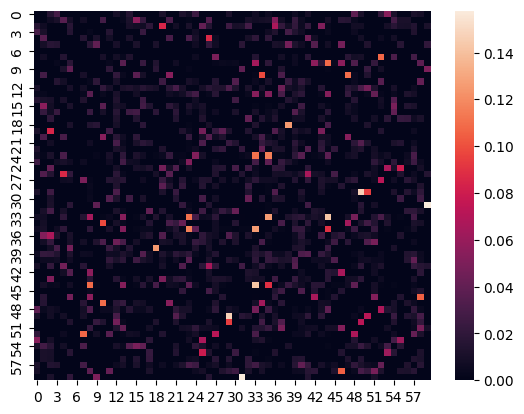

In [39]:
import seaborn
seaborn.heatmap(mat)

In [ ]:
clusterer = ExpertClusterer(model, )